In [1]:

from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
)

RANDOM_STATE = 42

# Find the project root from this notebook's location.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "artifacts").exists():
    PROJECT_ROOT = PROJECT_ROOT / "fraud-detection"

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Artifacts directory exists:", ARTIFACTS_DIR.exists())
print("Figures directory:", FIGURES_DIR)


Project root: c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection
Artifacts directory exists: True
Figures directory: c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\reports\figures


In [2]:

# Load trained models
logistic_model = joblib.load(ARTIFACTS_DIR / "logistic_regression.joblib")
tree_model = joblib.load(ARTIFACTS_DIR / "decision_tree.joblib")

# Load processed splits
train_df = pd.read_parquet(ARTIFACTS_DIR / "train_processed.parquet")
val_df = pd.read_parquet(ARTIFACTS_DIR / "validation_processed.parquet")
test_df = pd.read_parquet(ARTIFACTS_DIR / "test_processed.parquet")

# Separate features and target
X_train = train_df.drop(columns="Class")
y_train = train_df["Class"]

X_val = val_df.drop(columns="Class")
y_val = val_df["Class"]

X_test = test_df.drop(columns="Class")
y_test = test_df["Class"]

print("Models loaded:")
print("Logistic Regression:", type(logistic_model).__name__)
print("Decision Tree:", type(tree_model).__name__)

print("\nDataset shapes:")
print("Train:", X_train.shape, "| Fraud:", int(y_train.sum()))
print("Validation:", X_val.shape, "| Fraud:", int(y_val.sum()))
print("Test:", X_test.shape, "| Fraud:", int(y_test.sum()))

print("\nFeature columns match:",
      list(X_train.columns) == list(X_val.columns) == list(X_test.columns))
print("All splits contain finite values:",
      np.isfinite(X_train.to_numpy()).all()
      and np.isfinite(X_val.to_numpy()).all()
      and np.isfinite(X_test.to_numpy()).all())


Models loaded:
Logistic Regression: LogisticRegression
Decision Tree: DecisionTreeClassifier

Dataset shapes:
Train: (198608, 30) | Fraud: 331
Validation: (42559, 30) | Fraud: 71
Test: (42559, 30) | Fraud: 71

Feature columns match: True
All splits contain finite values: True


In [3]:

# Generate validation probabilities and default-threshold predictions
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
}

validation_probabilities = {}
validation_predictions = {}
baseline_results = []

for model_name, model in models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    validation_probabilities[model_name] = probabilities
    validation_predictions[model_name] = predictions

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    baseline_results.append({
        "Model": model_name,
        "Threshold": 0.5,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "Average Precision": average_precision_score(
            y_val, probabilities
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
    })

baseline_df = pd.DataFrame(baseline_results)
display(baseline_df.round(4))


,Model,Threshold,Precision,Recall,F1,Average Precision,TP,FP,FN,TN
0,Logistic Regression,0.5,0.0613,0.9155,0.1149,0.7196,65,995,6,41493
1,Decision Tree,0.5,0.0731,0.9014,0.1353,0.4744,64,811,7,41677


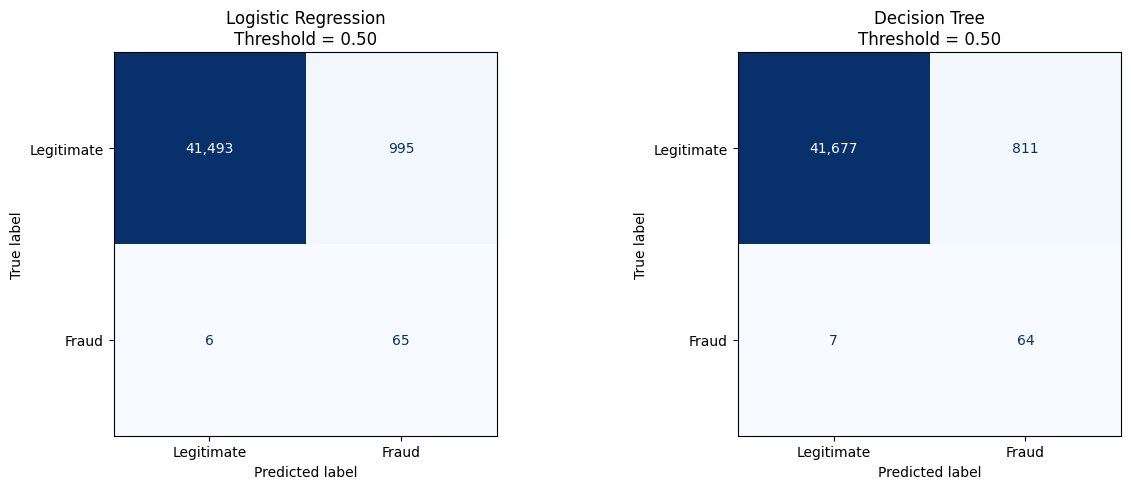

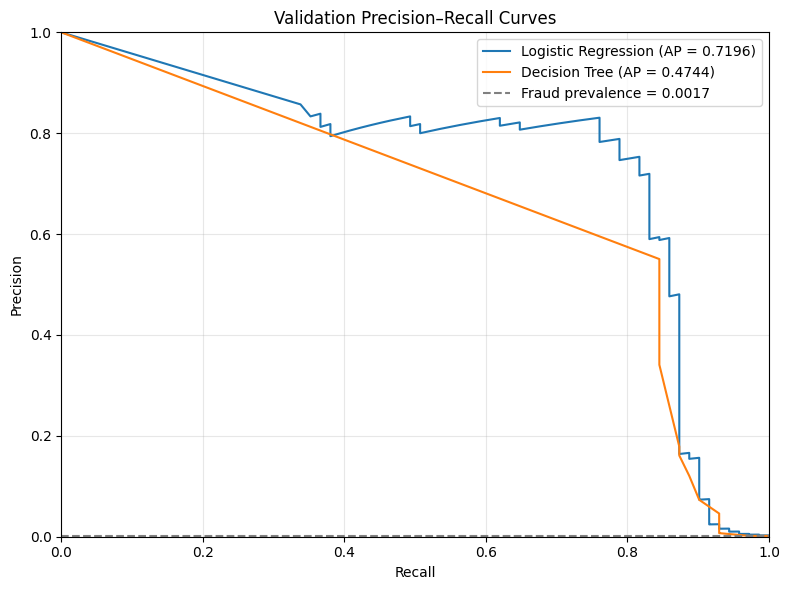

Saved validation plots to: c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\reports\figures


In [4]:

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (model_name, predictions) in zip(
    axes, validation_predictions.items()
):
    cm = confusion_matrix(y_val, predictions, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate", "Fraud"],
    )
    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format=",d",
        colorbar=False,
    )
    ax.set_title(f"{model_name}\nThreshold = 0.50")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "validation_confusion_matrices.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


fig, ax = plt.subplots(figsize=(8, 6))

for model_name, probabilities in validation_probabilities.items():
    precision, recall, _ = precision_recall_curve(
        y_val, probabilities
    )
    ap = average_precision_score(y_val, probabilities)

    ax.plot(
        recall,
        precision,
        label=f"{model_name} (AP = {ap:.4f})",
    )

# Baseline precision equals the fraud prevalence in the validation set.
baseline_prevalence = y_val.mean()
ax.axhline(
    baseline_prevalence,
    linestyle="--",
    color="gray",
    label=f"Fraud prevalence = {baseline_prevalence:.4f}",
)

ax.set(
    xlabel="Recall",
    ylabel="Precision",
    title="Validation Precision–Recall Curves",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "validation_precision_recall.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

print("Saved validation plots to:", FIGURES_DIR)


,Model,Best Threshold,TP,FP,FN,Recall,Precision,Minimum Validation Cost ($)
0,Logistic Regression,0.982,62,68,9,0.8732,0.4769,10700
1,Decision Tree,0.998,60,49,11,0.8451,0.5505,12225


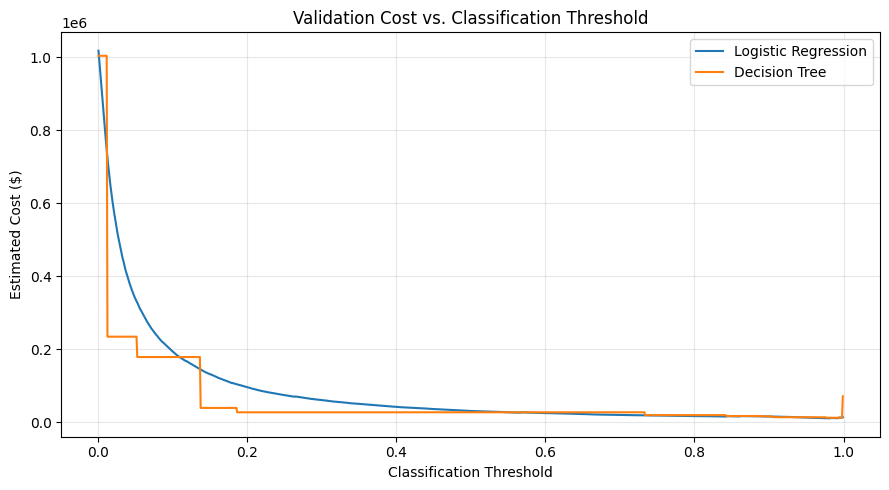

In [5]:

COST_FN = 1000
COST_FP = 25

threshold_grid = np.arange(0.001, 1.000, 0.001)
cost_results = []
threshold_cost_curves = {}

for model_name, probabilities in validation_probabilities.items():
    rows = []

    for threshold in threshold_grid:
        predictions = (probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        rows.append({
            "Threshold": threshold,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "Recall": tp / (tp + fn) if (tp + fn) else 0,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Total Cost ($)": COST_FN * fn + COST_FP * fp,
        })

    curve_df = pd.DataFrame(rows)
    threshold_cost_curves[model_name] = curve_df

    best = curve_df.sort_values(
        ["Total Cost ($)", "Threshold"],
        ascending=[True, False],
    ).iloc[0]

    cost_results.append({
        "Model": model_name,
        "Best Threshold": best["Threshold"],
        "TP": int(best["TP"]),
        "FP": int(best["FP"]),
        "FN": int(best["FN"]),
        "Recall": best["Recall"],
        "Precision": best["Precision"],
        "Minimum Validation Cost ($)": int(best["Total Cost ($)"]),
    })

cost_comparison_df = pd.DataFrame(cost_results)
display(cost_comparison_df.round(4))

# Plot validation cost against threshold for both models.
fig, ax = plt.subplots(figsize=(9, 5))

for model_name, curve_df in threshold_cost_curves.items():
    ax.plot(
        curve_df["Threshold"],
        curve_df["Total Cost ($)"],
        label=model_name,
    )

ax.set(
    xlabel="Classification Threshold",
    ylabel="Estimated Cost ($)",
    title="Validation Cost vs. Classification Threshold",
)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "validation_cost_vs_threshold.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


In [6]:

FINAL_MODEL_NAME = "Logistic Regression"
FINAL_THRESHOLD = 0.982
COST_FN = 1000
COST_FP = 25

final_model = logistic_model

# One final evaluation on the held-out test set
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= FINAL_THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
).ravel()

test_results = pd.DataFrame([{
    "Model": FINAL_MODEL_NAME,
    "Threshold": FINAL_THRESHOLD,
    "Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test, test_probabilities
    ),
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn,
    "Estimated Cost ($)": COST_FN * fn + COST_FP * fp,
}])

display(test_results.round(4))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0,
))

print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_test, test_predictions, labels=[0, 1]))


,Model,Threshold,Precision,Recall,F1,Average Precision,TP,FP,FN,TN,Estimated Cost ($)
0,Logistic Regression,0.982,0.5135,0.8028,0.6264,0.6316,57,54,14,42434,15350



Classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42488
       Fraud       0.51      0.80      0.63        71

    accuracy                           1.00     42559
   macro avg       0.76      0.90      0.81     42559
weighted avg       1.00      1.00      1.00     42559

Confusion matrix (actual rows, predicted columns):
[[42434    54]
 [   14    57]]


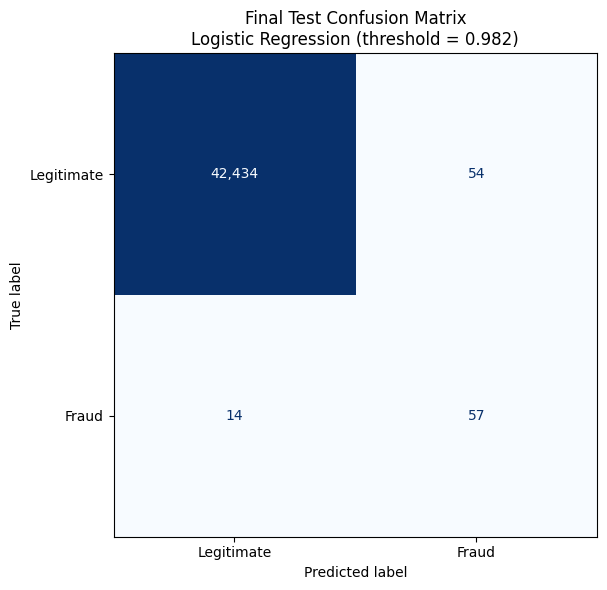

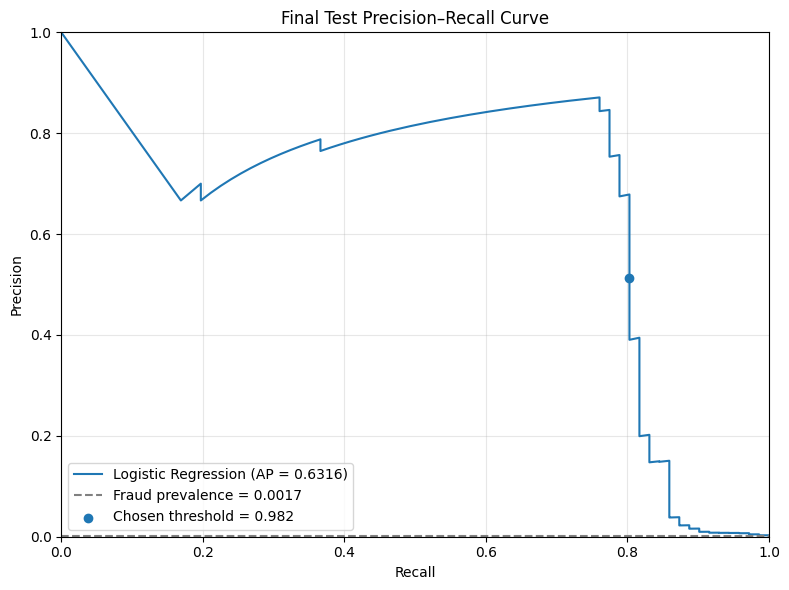

Saved final test plots to: c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\reports\figures


In [7]:

from sklearn.metrics import ConfusionMatrixDisplay

# Test confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format=",d",
    colorbar=False,
    ax=ax,
)

ax.set_title(
    f"Final Test Confusion Matrix\n"
    f"Logistic Regression (threshold = {FINAL_THRESHOLD:.3f})"
)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "test_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


# Test Precision–Recall curve
test_precision_curve, test_recall_curve, _ = precision_recall_curve(
    y_test, test_probabilities
)
test_ap = average_precision_score(y_test, test_probabilities)
test_prevalence = y_test.mean()

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    test_recall_curve,
    test_precision_curve,
    label=f"Logistic Regression (AP = {test_ap:.4f})",
)
ax.axhline(
    test_prevalence,
    linestyle="--",
    color="gray",
    label=f"Fraud prevalence = {test_prevalence:.4f}",
)

ax.scatter(
    recall_score(y_test, test_predictions),
    precision_score(y_test, test_predictions, zero_division=0),
    label=f"Chosen threshold = {FINAL_THRESHOLD:.3f}",
    zorder=3,
)

ax.set(
    xlabel="Recall",
    ylabel="Precision",
    title="Final Test Precision–Recall Curve",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "test_precision_recall.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()

print("Saved final test plots to:", FIGURES_DIR)


In [8]:

# Save evaluation tables for the project report
baseline_df.to_csv(
    FIGURES_DIR.parent / "validation_baseline_metrics.csv",
    index=False,
)

cost_comparison_df.to_csv(
    FIGURES_DIR.parent / "validation_cost_comparison.csv",
    index=False,
)

test_results.to_csv(
    FIGURES_DIR.parent / "final_test_metrics.csv",
    index=False,
)

# Save a concise human-readable summary
summary_path = FIGURES_DIR.parent / "evaluation_summary.txt"

with open(summary_path, "w", encoding="utf-8") as file:
    file.write("CREDIT CARD FRAUD DETECTION — EVALUATION SUMMARY\n")
    file.write("=" * 52 + "\n\n")

    file.write("Selected model: Logistic Regression\n")
    file.write(f"Selected threshold: {FINAL_THRESHOLD:.3f}\n")
    file.write("Threshold selected using validation data only.\n\n")

    file.write("Illustrative cost assumptions:\n")
    file.write(f"Missed fraud (FN): ${COST_FN:,}\n")
    file.write(f"False positive (FP): ${COST_FP:,}\n")
    file.write("True positive / true negative incremental cost: $0\n\n")

    file.write("Final held-out test results:\n")
    for column in [
        "Precision", "Recall", "F1", "Average Precision",
        "TP", "FP", "FN", "TN", "Estimated Cost ($)"
    ]:
        file.write(f"{column}: {test_results.iloc[0][column]}\n")

print("Saved evaluation files:")
print(FIGURES_DIR.parent / "validation_baseline_metrics.csv")
print(FIGURES_DIR.parent / "validation_cost_comparison.csv")
print(FIGURES_DIR.parent / "final_test_metrics.csv")
print(summary_path)


Saved evaluation files:
c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\reports\validation_baseline_metrics.csv
c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\reports\validation_cost_comparison.csv
c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\reports\final_test_metrics.csv
c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\reports\evaluation_summary.txt


In [11]:

import importlib.util
import joblib

print("SHAP installed:", importlib.util.find_spec("shap") is not None)

scaler = joblib.load(ARTIFACTS_DIR / "robust_scaler.joblib")
print("Loaded scaler:", type(scaler).__name__)
print("Scaled features:", list(scaler.feature_names_in_))


SHAP installed: True
Loaded scaler: RobustScaler
Scaled features: ['Time', 'Amount']


In [12]:

import shap

# Small samples to keep computation and memory usage low
background = X_train.sample(n=100, random_state=42)
explain_sample = X_val.sample(n=100, random_state=42)

# Explain the Logistic Regression model's fraud probabilities
explainer = shap.LinearExplainer(logistic_model, background)
shap_values = explainer(explain_sample)

print("SHAP calculation complete.")
print("Explained rows:", explain_sample.shape[0])
print("Features:", explain_sample.shape[1])
print("SHAP values shape:", shap_values.values.shape)


SHAP calculation complete.
Explained rows: 100
Features: 30
SHAP values shape: (100, 30)


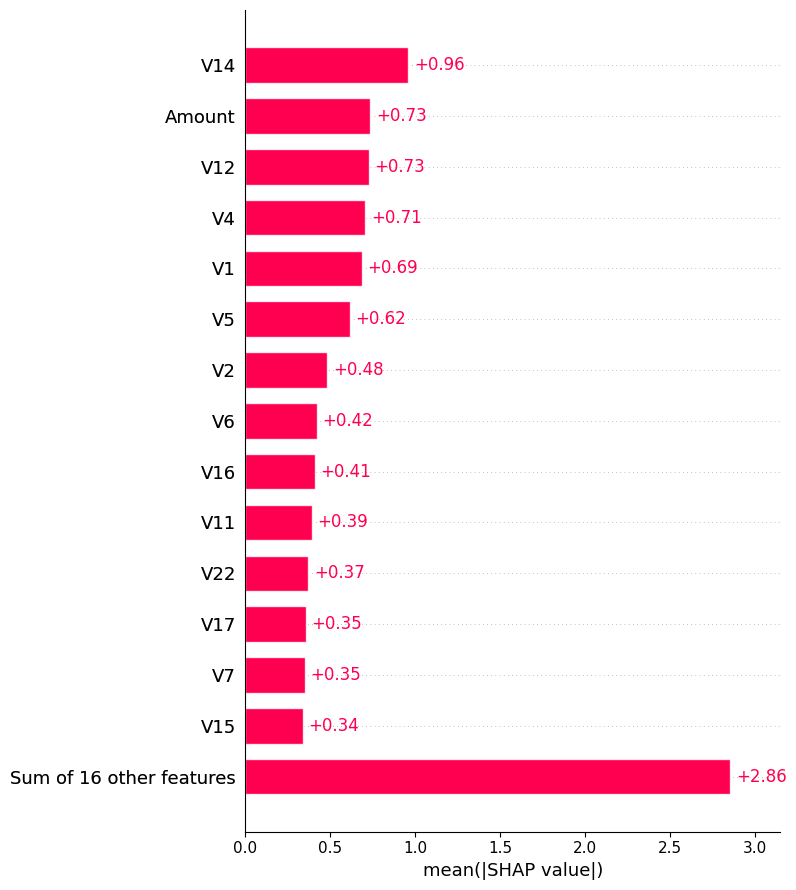

Saved SHAP feature importance: c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\reports\figures\shap_feature_importance.png


In [13]:

plt.figure()
shap.plots.bar(shap_values, max_display=15, show=False)
plt.tight_layout()

shap_summary_path = FIGURES_DIR / "shap_feature_importance.png"
plt.savefig(shap_summary_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Saved SHAP feature importance:", shap_summary_path)


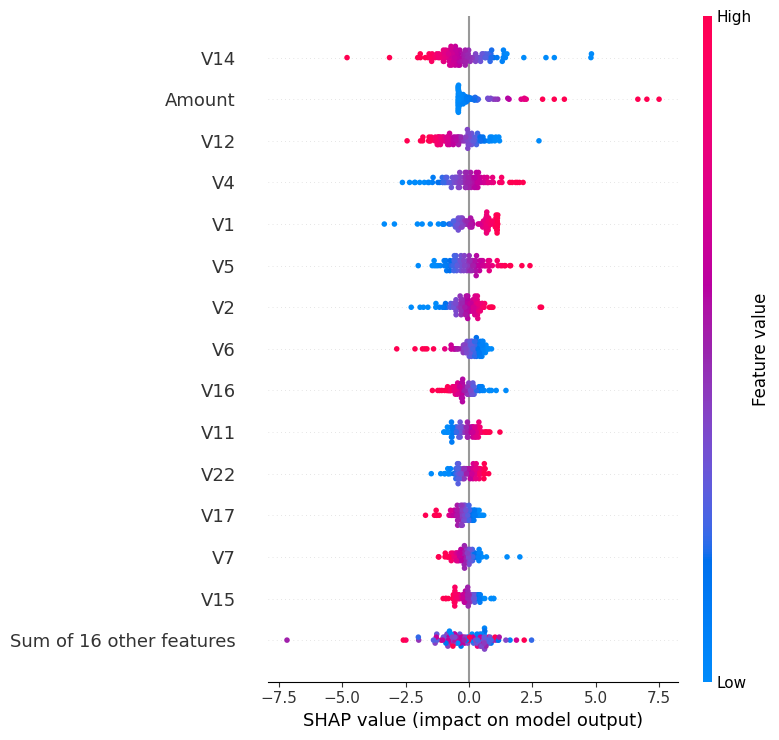

Saved SHAP beeswarm plot: c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\reports\figures\shap_beeswarm.png


In [14]:

plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.tight_layout()

shap_beeswarm_path = FIGURES_DIR / "shap_beeswarm.png"
plt.savefig(shap_beeswarm_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Saved SHAP beeswarm plot:", shap_beeswarm_path)


In [15]:

# Select the validation transaction with the highest predicted fraud probability
individual_idx = int(np.argmax(validation_probabilities["Logistic Regression"]))

individual_transaction = explain_sample.iloc[[0]].copy()

# Use the transaction at the highest-scoring validation index instead
individual_transaction = X_val.iloc[[individual_idx]]

individual_explanation = explainer(individual_transaction)

print("Validation row position:", individual_idx)
print(
    "Predicted fraud probability:",
    round(float(validation_probabilities["Logistic Regression"][individual_idx]), 4)
)
print("Actual class:", int(y_val.iloc[individual_idx]))


Validation row position: 1298
Predicted fraud probability: 1.0
Actual class: 1


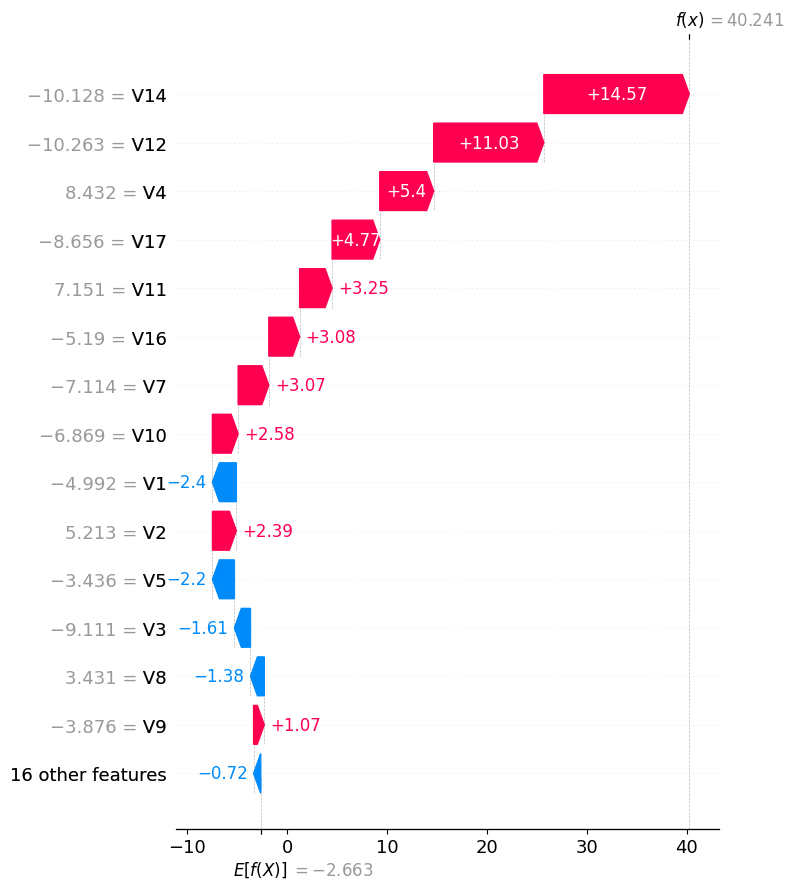

Saved individual SHAP explanation: c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\reports\figures\shap_individual_waterfall.png


In [16]:

plt.figure()
shap.plots.waterfall(individual_explanation[0], max_display=15, show=False)
plt.tight_layout()

waterfall_path = FIGURES_DIR / "shap_individual_waterfall.png"
plt.savefig(waterfall_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close()

print("Saved individual SHAP explanation:", waterfall_path)


In [17]:

individual_shap_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Feature Value": individual_transaction.iloc[0].values,
    "SHAP Value": individual_explanation.values[0],
})

individual_shap_df["Absolute SHAP"] = individual_shap_df["SHAP Value"].abs()
individual_shap_df = individual_shap_df.sort_values(
    "Absolute SHAP", ascending=False
)

shap_report_path = ARTIFACTS_DIR / "individual_shap_explanation.csv"
individual_shap_df.to_csv(shap_report_path, index=False)

display(individual_shap_df.head(10).round(5))
print("Saved individual SHAP report:", shap_report_path)


,Feature,Feature Value,SHAP Value,Absolute SHAP
14,V14,-10.12752,14.56562,14.56562
12,V12,-10.26298,11.02669,11.02669
4,V4,8.43199,5.40213,5.40213
17,V17,-8.65571,4.77060,4.77060
11,V11,7.15063,3.25071,3.25071
16,V16,-5.19027,3.08482,3.08482
7,V7,-7.11430,3.06992,3.06992
10,V10,-6.86851,2.57809,2.57809
1,V1,-4.99176,-2.39810,2.39810
2,V2,5.21334,2.39058,2.39058


Saved individual SHAP report: c:\Users\Administrator\Self Study\fraud_detection\fraud-detection\fraud-detection\artifacts\individual_shap_explanation.csv


In [18]:

required_artifacts = [
    "logistic_regression.joblib",
    "decision_tree.joblib",
    "robust_scaler.joblib",
    "train_processed.parquet",
    "validation_processed.parquet",
    "test_processed.parquet",
]

artifact_status = pd.DataFrame([
    {
        "Artifact": filename,
        "Exists": (ARTIFACTS_DIR / filename).exists(),
        "Size (KB)": (
            round((ARTIFACTS_DIR / filename).stat().st_size / 1024, 2)
            if (ARTIFACTS_DIR / filename).exists()
            else None
        ),
    }
    for filename in required_artifacts
])

display(artifact_status)


,Artifact,Exists,Size (KB)
0,logistic_regression.joblib,True,1.50
1,decision_tree.joblib,True,5.51
2,robust_scaler.joblib,True,0.79
3,train_processed.parquet,True,52341.53
4,validation_processed.parquet,True,12032.25
5,test_processed.parquet,True,12025.67


In [19]:

# Reload the saved scaler to verify the actual deployment artifact
loaded_scaler = joblib.load(ARTIFACTS_DIR / "robust_scaler.joblib")

# Reconstruct raw validation features from the original dataset
# using the same deduplication and split procedure as Notebook 2.
raw_df = pd.read_csv(PROJECT_ROOT / "data" / "creditcard.csv")
raw_df = raw_df.drop_duplicates().reset_index(drop=True)

from sklearn.model_selection import train_test_split

X_raw = raw_df.drop(columns="Class")
y_raw = raw_df["Class"]

X_raw_train_val, X_raw_test, y_raw_train_val, y_raw_test = train_test_split(
    X_raw, y_raw, test_size=0.15, stratify=y_raw, random_state=RANDOM_STATE
)
X_raw_train, X_raw_val, y_raw_train, y_raw_val = train_test_split(
    X_raw_train_val,
    y_raw_train_val,
    test_size=0.15 / 0.85,
    stratify=y_raw_train_val,
    random_state=RANDOM_STATE,
)

# Scale only the two columns that were transformed in training
X_raw_val_scaled = X_raw_val.copy()
X_raw_val_scaled[["Time", "Amount"]] = loaded_scaler.transform(
    X_raw_val[["Time", "Amount"]]
)

# Check alignment with the saved validation split
print("Same row count:", len(X_raw_val_scaled) == len(X_val))
print("Same feature order:", list(X_raw_val_scaled.columns) == list(X_val.columns))
print(
    "Maximum absolute difference:",
    float(np.max(np.abs(X_raw_val_scaled.to_numpy() - X_val.to_numpy())))
)


Same row count: True
Same feature order: True
Maximum absolute difference: 0.0
